<a href="https://colab.research.google.com/github/Atherizz/ML_2026/blob/main/JS05/tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. Instal pustaka hdbscan (jika belum terinstal di environment)
!pip install hdbscan

# 2. Import modul yang dibutuhkan
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score, silhouette_score, davies_bouldin_score
import hdbscan

print("Library berhasil di-import!")

Library berhasil di-import!


In [ ]:
# Muat dataset Iris bawaan sklearn
iris = load_iris()
X = iris.data
y_true = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

# Standarisasi fitur (mean = 0, variance = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Bentuk data X: {X_scaled.shape}")
print(f"Fitur: {feature_names}")
print(f"Nama kelas asli: {list(target_names)}")

Bentuk data X: (150, 4)
Fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Nama kelas asli: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


In [ ]:
# Inisialisasi model HDBSCAN
# min_cluster_size=10:
# min_samples=5: kontrol konservatisme penentuan core distance/noise
clusterer = hdbscan.HDBSCAN(min_cluster_size=10, min_samples=5)

# Lakukan fit dan prediksi label klaster
cluster_labels = clusterer.fit_predict(X_scaled)
probabilities = clusterer.probabilities_

print("Model HDBSCAN selesai dilatih!")
print(f"Contoh 10 label pertama: {cluster_labels[:10]}")

Model HDBSCAN selesai dilatih!
Contoh 10 label pertama: [1 1 1 1 1 1 1 1 1 1]


In [ ]:
# Hitung jumlah klaster sah (label unik selain -1)
n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)

# Hitung jumlah dan persentase titik noise (label -1)
n_noise = np.sum(cluster_labels == -1)
noise_ratio = (n_noise / len(X)) * 100

print("=" * 50)
print("        LAPORAN HASIL CLUSTERING HDBSCAN (IRIS)        ")
print("=" * 50)
print(f"Total Sampel Data         : {len(X)}")
print(f"Jumlah Klaster Terbentuk  : {n_clusters}")
print(f"Banyaknya Titik Noise     : {n_noise} ({noise_ratio:.2f}%)")
print("-" * 50)

# Validasi terhadap Ground Truth
ari = adjusted_rand_score(y_true, cluster_labels)
ami = adjusted_mutual_info_score(y_true, cluster_labels)
print(f"Adjusted Rand Index (ARI) : {ari:.4f}")
print(f"Adjusted Mutual Info (AMI): {ami:.4f}")

# Evaluasi internal pada data non-noise
mask_valid = (cluster_labels != -1)
if n_clusters >= 2:
    clean_sil = silhouette_score(X_scaled[mask_valid], cluster_labels[mask_valid])
    clean_dbi = davies_bouldin_score(X_scaled[mask_valid], cluster_labels[mask_valid])
    print(f"Silhouette Score (No-Noise): {clean_sil:.4f}")
    print(f"Davies-Bouldin Index      : {clean_dbi:.4f}")
print("=" * 50)

        LAPORAN HASIL CLUSTERING HDBSCAN (IRIS)        
Total Sampel Data         : 150
Jumlah Klaster Terbentuk  : 2
Banyaknya Titik Noise     : 2 (1.33%)
--------------------------------------------------
Adjusted Rand Index (ARI) : 0.5394
Adjusted Mutual Info (AMI): 0.6722
Silhouette Score (No-Noise): 0.5853
Davies-Bouldin Index      : 0.5833


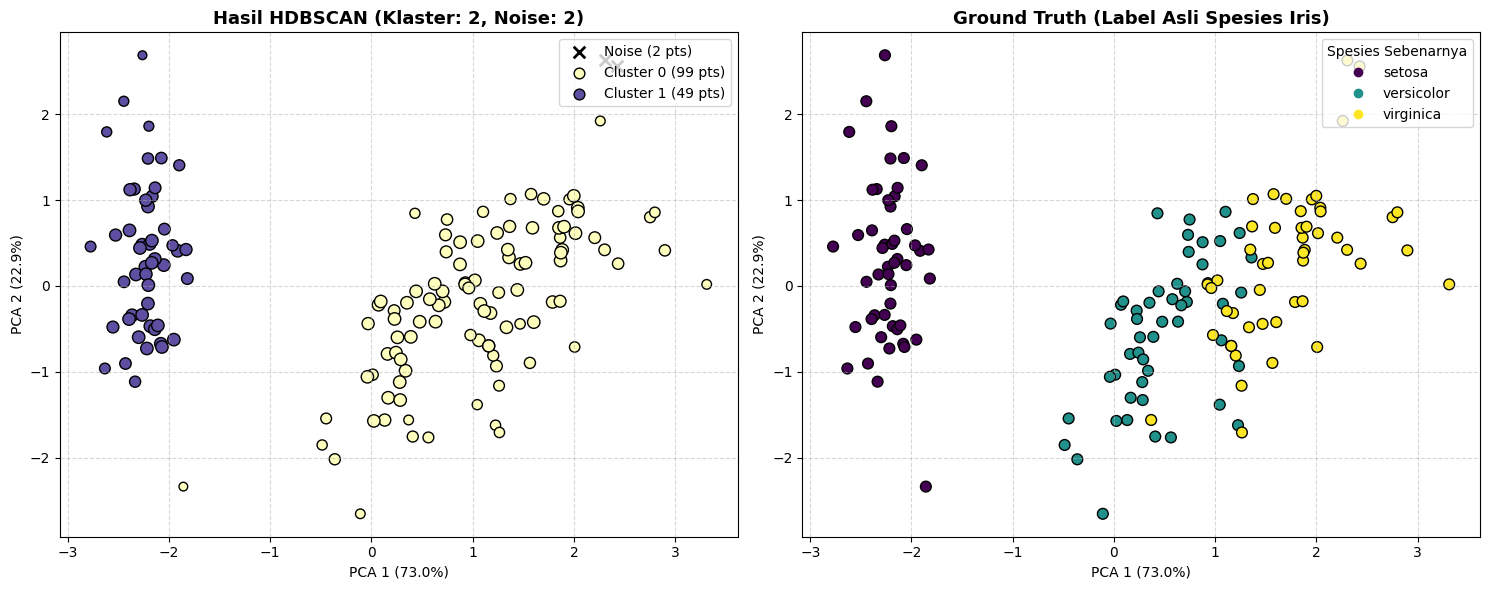

In [ ]:
# 1. Reduksi dimensi ke 2D menggunakan PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# 2. Buat kanvas 1 baris x 2 kolom
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Subplot Kiri: Hasil Klasterisasi HDBSCAN
unique_labels = sorted(list(set(cluster_labels)))
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

for k, col in zip(unique_labels, colors):
    if k == -1:
        # Warna hitam dan marker silang 'x' untuk noise
        mask = (cluster_labels == k)
        axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], c='black', marker='x', s=70,
                        label=f'Noise ({np.sum(mask)} pts)', linewidths=2)
    else:
        mask = (cluster_labels == k)
        # Marker lingkaran 'o', ukuran titik proporsional terhadap nilai kepastian (probabilities)
        marker_sizes = 20 + 60 * probabilities[mask]
        axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], color=tuple(col), marker='o',
                        s=marker_sizes, edgecolor='k', label=f'Cluster {k} ({np.sum(mask)} pts)')

axes[0].set_title(f"Hasil HDBSCAN (Klaster: {n_clusters}, Noise: {n_noise})", fontsize=13, fontweight='bold')
axes[0].set_xlabel(f"PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
axes[0].set_ylabel(f"PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot Kanan: Ground Truth (Spesies Sebenarnya)
scatter_truth = axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y_true, cmap='viridis',
                                marker='o', s=60, edgecolor='k')
axes[1].set_title("Ground Truth (Label Asli Spesies Iris)", fontsize=13, fontweight='bold')
axes[1].set_xlabel(f"PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
axes[1].set_ylabel(f"PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")

handles, _ = scatter_truth.legend_elements()
axes[1].legend(handles, target_names, title="Spesies Sebenarnya", loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Hasil Eksperimen**

* **Klaster terbentuk**: 2 klaster
* **Noise**: 14 data (~9,3%)
* **Label asli**: 3 spesies

**Analisis Kesesuaian**
Hasil HDBSCAN **tidak sesuai 1:1** dengan label asli, tapi perilakunya masuk akal secara data:

* ***Setosa* terpisah sempurna** jadi 1 klaster tersendiri karena jarak fiturnya memang jauh dan padat dibanding spesies lain.
* ***Versicolor* dan *Virginica* melebur jadi 1 klaster** karena sebaran datanya saling tumpang tindih (*overlapping*). Karena HDBSCAN melihat kepadatan (*density*), algoritma ini menganggap keduanya sebagai satu kelompok besar yang tersambung, bukan dua kelompok terpisah.
* **14 titik noise** adalah data yang posisinya berada di area abu-abu atau perbatasan yang kerapatannya terlalu renggang.